In [4]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

In [14]:
import csv
import pandas as pd
from io import StringIO

ruta_archivo = "ca_cliente_psm_did.csv"

# Leer el archivo como texto
with open(
    ruta_archivo,
    "r",
    encoding="utf-8-sig"
) as archivo:
    lineas = archivo.readlines()

# El encabezado ya está correctamente separado
encabezado = lineas[0].strip()

lineas_corregidas = [encabezado]

for linea in lineas[1:]:

    linea = linea.strip()

    # Eliminar las comillas que rodean toda la fila
    if linea.startswith('"') and linea.endswith('"'):
        linea = linea[1:-1]

    # Convertir comillas dobles escapadas:
    # ""5,90"" -> "5,90"
    linea = linea.replace('""', '"')

    lineas_corregidas.append(linea)

texto_corregido = "\n".join(lineas_corregidas)

df = pd.read_csv(
    StringIO(texto_corregido),
    sep=",",
    quotechar='"',
    dtype=str
)

print(df.shape)
print(df.columns.tolist())
print(df.head())

(7695, 13)
['codigo_cliente', 'cliente_etica', 'canal', 'cohorte_año', 'antiguedad_meses', 'fecha_primer_etica', 'venta_historica', 'log_venta_historica', 'productos_no_etica_historicos', 'lineas_historicas', 'frecuencia_historica', 'meses_activos_historicos', 'venta_mensual_promedio_historica']
  codigo_cliente cliente_etica               canal cohorte_año  \
0    C0000000000             1  VENTAS AL PERSONAL        2022   
1    C1000043029             1     INSTITUCIONALES        2022   
2    C1000069024             0     CLIENTES VARIOS        2022   
3    C1000081023             1        LICITACIONES        2022   
4    C1000089020             1            CLINICAS        2024   

  antiguedad_meses fecha_primer_etica venta_historica log_venta_historica  \
0               47         2022-09-16     797324.0461   5,901635406652216   
1               48         2022-07-12      99151.3300   4,996302924232227   
2               45                NaN       1468.7200  3,1672346041103596  

In [15]:
import numpy as np

df.columns = (
    df.columns
    .astype(str)
    .str.strip()
    .str.replace("\ufeff", "", regex=False)
)

# Reemplazar valores NULL
df = df.replace({
    "NULL": np.nan,
    "null": np.nan,
    "None": np.nan,
    "": np.nan
})

# Limpiar variables de texto
df["codigo_cliente"] = (
    df["codigo_cliente"]
    .astype(str)
    .str.strip()
)

df["canal"] = (
    df["canal"]
    .astype(str)
    .str.strip()
)

In [16]:
columnas_numericas = [
    "cliente_etica",
    "cohorte_año",
    "antiguedad_meses",
    "venta_historica",
    "log_venta_historica",
    "productos_no_etica_historicos",
    "lineas_historicas",
    "frecuencia_historica",
    "meses_activos_historicos",
    "venta_mensual_promedio_historica"
]

for columna in columnas_numericas:

    df[columna] = (
        df[columna]
        .astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    df[columna] = pd.to_numeric(
        df[columna],
        errors="coerce"
    )

In [17]:
df["fecha_primer_etica"] = pd.to_datetime(
    df["fecha_primer_etica"],
    errors="coerce"
)

In [18]:
columnas_psm = [
    "codigo_cliente",
    "cliente_etica",
    "canal",
    "cohorte_año",
    "antiguedad_meses",
    "fecha_primer_etica",
    "log_venta_historica"
]

df_psm = df.dropna(
    subset=[
        "codigo_cliente",
        "cliente_etica",
        "canal",
        "cohorte_año",
        "antiguedad_meses",
        "log_venta_historica"
    ]
).copy()

df_psm["codigo_cliente"] = (
    df_psm["codigo_cliente"]
    .astype(str)
    .str.strip()
)

df_psm["canal"] = (
    df_psm["canal"]
    .astype(str)
    .str.strip()
)

df_psm["cliente_etica"] = pd.to_numeric(
    df_psm["cliente_etica"],
    errors="coerce"
).astype(int)

df_psm["cohorte_año"] = pd.to_numeric(
    df_psm["cohorte_año"],
    errors="coerce"
).astype(int)

df_psm["antiguedad_meses"] = pd.to_numeric(
    df_psm["antiguedad_meses"],
    errors="coerce"
)

df_psm["log_venta_historica"] = pd.to_numeric(
    df_psm["log_venta_historica"],
    errors="coerce"
)

df_psm["fecha_primer_etica"] = pd.to_datetime(
    df_psm["fecha_primer_etica"],
    errors="coerce"
)

print(df_psm.shape)
print(df_psm["cliente_etica"].value_counts())

(7695, 13)
cliente_etica
1    5978
0    1717
Name: count, dtype: int64


In [19]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df_psm = df.copy()

# Limpiar nombres de columnas
df_psm.columns = (
    df_psm.columns
    .astype(str)
    .str.strip()
)

# Limpiar texto
df_psm["codigo_cliente"] = (
    df_psm["codigo_cliente"]
    .astype(str)
    .str.strip()
)

df_psm["canal"] = (
    df_psm["canal"]
    .astype(str)
    .str.strip()
)

# Reemplazar cadenas inválidas
df_psm["canal"] = df_psm["canal"].replace({
    "": np.nan,
    "nan": np.nan,
    "None": np.nan,
    "NULL": np.nan
})

# Convertir variables numéricas
columnas_numericas = [
    "cliente_etica",
    "cohorte_año",
    "antiguedad_meses",
    "log_venta_historica"
]

for columna in columnas_numericas:

    df_psm[columna] = (
        df_psm[columna]
        .astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    df_psm[columna] = pd.to_numeric(
        df_psm[columna],
        errors="coerce"
    )

# Convertir fecha
df_psm["fecha_primer_etica"] = pd.to_datetime(
    df_psm["fecha_primer_etica"],
    errors="coerce"
)

# Eliminar faltantes solamente después de convertir
df_psm = df_psm.dropna(
    subset=[
        "codigo_cliente",
        "cliente_etica",
        "canal",
        "cohorte_año",
        "antiguedad_meses",
        "log_venta_historica"
    ]
).copy()

# Conservar solamente valores válidos de tratamiento
df_psm = df_psm[
    df_psm["cliente_etica"].isin([0, 1])
].copy()

# Convertir enteros al final
df_psm["cliente_etica"] = (
    df_psm["cliente_etica"].astype(int)
)

df_psm["cohorte_año"] = (
    df_psm["cohorte_año"].astype(int)
)

# Declarar categóricas explícitamente
df_psm["canal"] = df_psm["canal"].astype("category")
df_psm["cohorte_año"] = df_psm["cohorte_año"].astype("category")

In [20]:
print("Dimensión:", df_psm.shape)

print("\nCliente Ética:")
print(df_psm["cliente_etica"].value_counts(dropna=False))

print("\nCanales:")
print(df_psm["canal"].value_counts(dropna=False))

print("\nCohortes:")
print(df_psm["cohorte_año"].value_counts(dropna=False))

print("\nCantidad de categorías:")
print("Canal:", df_psm["canal"].nunique())
print("Cohorte:", df_psm["cohorte_año"].nunique())

Dimensión: (7695, 13)

Cliente Ética:
cliente_etica
1    5978
0    1717
Name: count, dtype: int64

Canales:
canal
FARMACIAS             5704
CLIENTES VARIOS        706
INSTITUCIONALES        390
CATALOGO               163
CLINICAS               154
MAYORISTAS             108
CORPORATIVO             90
LICITACIONES            72
VETERINARIAS            72
MEDICOS                 56
DISTRIBUIDORES          53
VENTAS MOSTRADOR        35
SUPERMERCADOS           32
MINI MAYORISTAS         28
CADENAS                 24
BEAUTY STORE             7
VENTAS AL PERSONAL       1
Name: count, dtype: int64

Cohortes:
cohorte_año
2022    4545
2023    1150
2024     939
2025     885
2026     176
Name: count, dtype: int64

Cantidad de categorías:
Canal: 17
Cohorte: 5


In [21]:
modelo_ps = smf.logit(
    formula="""
        cliente_etica
        ~ antiguedad_meses
        + log_venta_historica
        + C(canal)
        + C(cohorte_año)
    """,
    data=df_psm
).fit()

print(modelo_ps.summary())

         Current function value: 0.184963
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:          cliente_etica   No. Observations:                 7695
Model:                          Logit   Df Residuals:                     7672
Method:                           MLE   Df Model:                           22
Date:                Mon, 20 Jul 2026   Pseudo R-squ.:                  0.6516
Time:                        21:55:29   Log-Likelihood:                -1423.3
converged:                      False   LL-Null:                       -4084.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept                        -10.2035      1.490     -6.848      0.000     -13.124      -7.283
C(can

c:\Users\Usuario\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [22]:
df_psm["propensity_score"] = modelo_ps.predict(df_psm)

print(df_psm["propensity_score"].describe())

print(
    df_psm.groupby("cliente_etica")[
        "propensity_score"
    ].describe()
)

count    7.695000e+03
mean     7.768681e-01
std      3.473747e-01
min      3.402872e-13
25%      7.686882e-01
50%      9.605959e-01
75%      9.892962e-01
max      1.000000e+00
Name: propensity_score, dtype: float64
                count      mean       std           min       25%       50%  \
cliente_etica                                                                 
0              1717.0  0.238117  0.331180  3.402872e-13  0.001429  0.029169   
1              5978.0  0.931608  0.128513  1.437205e-03  0.934817  0.978455   

                    75%       max  
cliente_etica                      
0              0.503238  0.998909  
1              0.992402  1.000000  


In [23]:
import numpy as np

epsilon = 1e-6

df_psm["propensity_score"] = (
    df_psm["propensity_score"]
    .clip(epsilon, 1 - epsilon)
)

df_psm["logit_ps"] = np.log(
    df_psm["propensity_score"]
    /
    (1 - df_psm["propensity_score"])
)

print(df_psm["logit_ps"].describe())

count    7695.000000
mean        1.901313
std         4.449156
min       -13.815510
25%         1.200919
50%         3.193685
75%         4.526399
max        13.815510
Name: logit_ps, dtype: float64


In [24]:
caliper = 0.20 * df_psm["logit_ps"].std(ddof=1)

print("Caliper:", round(caliper, 6))

Caliper: 0.889831


In [25]:
tratados_originales = df_psm[
    df_psm["cliente_etica"] == 1
].copy()

controles_originales = df_psm[
    df_psm["cliente_etica"] == 0
].copy()

limite_inferior = max(
    tratados_originales["propensity_score"].min(),
    controles_originales["propensity_score"].min()
)

limite_superior = min(
    tratados_originales["propensity_score"].max(),
    controles_originales["propensity_score"].max()
)

print(
    "Soporte común:",
    round(limite_inferior, 4),
    "-",
    round(limite_superior, 4)
)

Soporte común: 0.0014 - 0.9989


In [26]:
df_soporte = df_psm[
    df_psm["propensity_score"].between(
        limite_inferior,
        limite_superior,
        inclusive="both"
    )
].copy()

print(df_soporte.shape)

print(
    df_soporte["cliente_etica"].value_counts()
)

(7133, 15)
cliente_etica
1    5846
0    1287
Name: count, dtype: int64


In [27]:
def matching_exacto_sin_reemplazo(
    data,
    caliper,
    columnas_exactas=("canal", "cohorte_año"),
    random_state=42
):

    tratados = data[
        data["cliente_etica"] == 1
    ].copy()

    controles = data[
        data["cliente_etica"] == 0
    ].copy()

    tratados = tratados.sample(
        frac=1,
        random_state=random_state
    )

    controles_disponibles = set(
        controles.index
    )

    pares = []

    for idx_tratado, fila in tratados.iterrows():

        if not controles_disponibles:
            break

        candidatos = controles.loc[
            list(controles_disponibles)
        ].copy()

        for columna in columnas_exactas:

            candidatos = candidatos[
                candidatos[columna]
                == fila[columna]
            ]

        if candidatos.empty:
            continue

        distancia = (
            candidatos["logit_ps"]
            - fila["logit_ps"]
        ).abs()

        idx_control = distancia.idxmin()

        if distancia.loc[idx_control] <= caliper:

            pares.append({
                "indice_tratado": idx_tratado,
                "indice_control": idx_control,
                "distancia_logit": distancia.loc[idx_control]
            })

            controles_disponibles.remove(
                idx_control
            )

    return pd.DataFrame(pares)

In [28]:
pares_match = matching_exacto_sin_reemplazo(
    data=df_soporte,
    caliper=caliper,
    columnas_exactas=(
        "canal",
        "cohorte_año"
    )
)

print("Cantidad de parejas:", len(pares_match))

print(
    pares_match["distancia_logit"].describe()
)

Cantidad de parejas: 540
count    540.000000
mean       0.311048
std        0.284222
min        0.000011
25%        0.041230
50%        0.230689
75%        0.569942
max        0.889145
Name: distancia_logit, dtype: float64


In [29]:
matched_tratados = (
    df_soporte
    .loc[
        pares_match["indice_tratado"]
    ]
    .copy()
    .reset_index(drop=True)
)

matched_controles = (
    df_soporte
    .loc[
        pares_match["indice_control"]
    ]
    .copy()
    .reset_index(drop=True)
)

matched_tratados["id_pareja"] = np.arange(
    1,
    len(matched_tratados) + 1
)

matched_controles["id_pareja"] = np.arange(
    1,
    len(matched_controles) + 1
)

In [30]:
print("Tratados:", len(matched_tratados))
print("Controles:", len(matched_controles))

print(
    matched_controles["codigo_cliente"].nunique()
)

print(
    (
        matched_tratados["canal"].values
        ==
        matched_controles["canal"].values
    ).all()
)

print(
    (
        matched_tratados["cohorte_año"].values
        ==
        matched_controles["cohorte_año"].values
    ).all()
)

Tratados: 540
Controles: 540
540
True
True


In [31]:
import numpy as np
import pandas as pd

variables = [
    "antiguedad_meses",
    "log_venta_historica"
]

def smd(x1, x0):

    media1 = np.mean(x1)
    media0 = np.mean(x0)

    sd = np.sqrt(
        (
            np.var(x1, ddof=1)
            + np.var(x0, ddof=1)
        ) / 2
    )

    return (media1 - media0) / sd


balance = []

for variable in variables:

    antes = smd(
        df_psm.loc[
            df_psm["cliente_etica"] == 1,
            variable
        ],
        df_psm.loc[
            df_psm["cliente_etica"] == 0,
            variable
        ]
    )

    despues = smd(
        matched_tratados[variable],
        matched_controles[variable]
    )

    balance.append({
        "Variable": variable,
        "Antes": antes,
        "Después": despues
    })

balance = pd.DataFrame(balance)

print(balance.round(3))

              Variable  Antes  Después
0     antiguedad_meses  0.509    0.007
1  log_venta_historica  1.052    0.135


In [32]:
import numpy as np
import pandas as pd

# Asegurar que ambos DataFrames tengan el mismo orden
matched_tratados = matched_tratados.reset_index(drop=True).copy()
matched_controles = matched_controles.reset_index(drop=True).copy()

# Crear identificador de pareja
matched_tratados["id_pareja"] = np.arange(
    1,
    len(matched_tratados) + 1
)

matched_controles["id_pareja"] = np.arange(
    1,
    len(matched_controles) + 1
)

parejas_did = pd.DataFrame({
    "id_pareja": matched_tratados["id_pareja"],

    "cliente_tratado":
        matched_tratados["codigo_cliente"],

    "cliente_control":
        matched_controles["codigo_cliente"],

    "fecha_evento":
        matched_tratados["fecha_primer_etica"],

    "canal":
        matched_tratados["canal"],

    "cohorte_año":
        matched_tratados["cohorte_año"],

    "propensity_tratado":
        matched_tratados["propensity_score"],

    "propensity_control":
        matched_controles["propensity_score"],

    "logit_tratado":
        matched_tratados["logit_ps"],

    "logit_control":
        matched_controles["logit_ps"]
})

parejas_did["distancia_logit"] = (
    parejas_did["logit_tratado"]
    - parejas_did["logit_control"]
).abs()

print(parejas_did.shape)
print(parejas_did.head())
print(parejas_did.isna().sum())

(540, 11)
   id_pareja cliente_tratado cliente_control fecha_evento            canal  \
0          1     C9391812014     C5868879012   2024-02-07        FARMACIAS   
1          2     C5724930011     C3926023019   2022-07-20        FARMACIAS   
2          3     C4193264016      C177244029   2023-01-17  INSTITUCIONALES   
3          4     C8806933019     C1591996012   2023-05-30        FARMACIAS   
4          5     C8854132019     C3575931019   2022-08-08        FARMACIAS   

  cohorte_año  propensity_tratado  propensity_control  logit_tratado  \
0        2023            0.869828            0.871894       1.899442   
1        2022            0.984917            0.983811       4.179015   
2        2023            0.593400            0.627348       0.378039   
3        2022            0.979112            0.977057       3.847484   
4        2022            0.989638            0.988797       4.559214   

   logit_control  distancia_logit  
0       1.917808         0.018365  
1       4.107100

In [33]:
parejas_did["fecha_evento"] = pd.to_datetime(
    parejas_did["fecha_evento"],
    errors="coerce"
)

print(
    parejas_did["fecha_evento"]
    .describe()
)

print(
    parejas_did["fecha_evento"]
    .dt.year
    .value_counts()
    .sort_index()
)

count                    540
mean     2023-12-12 07:25:20
min      2022-07-06 00:00:00
25%      2022-10-18 18:00:00
50%      2023-07-19 00:00:00
75%      2025-03-18 00:00:00
max      2026-03-31 00:00:00
Name: fecha_evento, dtype: object
fecha_evento
2022    183
2023    131
2024     75
2025    113
2026     38
Name: count, dtype: int64


In [34]:
print(
    "Fechas nulas:",
    parejas_did["fecha_evento"].isna().sum()
)

print(
    "Clientes tratados únicos:",
    parejas_did["cliente_tratado"].nunique()
)

print(
    "Clientes control únicos:",
    parejas_did["cliente_control"].nunique()
)

Fechas nulas: 0
Clientes tratados únicos: 540
Clientes control únicos: 540


In [35]:
parejas_did.to_csv(
    "parejas_did.csv",
    index=False,
    encoding="utf-8-sig"
)

In [36]:
clientes_tratados = parejas_did[
    [
        "id_pareja",
        "cliente_tratado",
        "fecha_evento"
    ]
].copy()

clientes_tratados = clientes_tratados.rename(
    columns={
        "cliente_tratado": "codigo_cliente"
    }
)

clientes_tratados["tratamiento"] = 1


clientes_controles = parejas_did[
    [
        "id_pareja",
        "cliente_control",
        "fecha_evento"
    ]
].copy()

clientes_controles = clientes_controles.rename(
    columns={
        "cliente_control": "codigo_cliente"
    }
)

clientes_controles["tratamiento"] = 0

In [37]:
clientes_did = pd.concat(
    [
        clientes_tratados,
        clientes_controles
    ],
    ignore_index=True
)

clientes_did["fecha_evento"] = pd.to_datetime(
    clientes_did["fecha_evento"]
)

print(clientes_did.shape)
print(clientes_did.head())
print(clientes_did["tratamiento"].value_counts())

(1080, 4)
   id_pareja codigo_cliente fecha_evento  tratamiento
0          1    C9391812014   2024-02-07            1
1          2    C5724930011   2022-07-20            1
2          3    C4193264016   2023-01-17            1
3          4    C8806933019   2023-05-30            1
4          5    C8854132019   2022-08-08            1
tratamiento
1    540
0    540
Name: count, dtype: int64


In [38]:
clientes_did.to_csv(
    "clientes_did.csv",
    index=False,
    encoding="utf-8-sig"
)

Me fui a 10_desde_hasta.sql

In [44]:
pip install pyodbc

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Usuario\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [45]:
import pyodbc
import pandas as pd
import numpy as np

In [46]:
print(clientes_did.shape)
print(clientes_did.head())
print(clientes_did.dtypes)

(1080, 4)
   id_pareja codigo_cliente fecha_evento  tratamiento
0          1    C9391812014   2024-02-07            1
1          2    C5724930011   2022-07-20            1
2          3    C4193264016   2023-01-17            1
3          4    C8806933019   2023-05-30            1
4          5    C8854132019   2022-08-08            1
id_pareja                  int32
codigo_cliente            object
fecha_evento      datetime64[ns]
tratamiento                int64
dtype: object


In [47]:
clientes_did_sql = clientes_did[
    [
        "id_pareja",
        "codigo_cliente",
        "tratamiento",
        "fecha_evento"
    ]
].copy()

clientes_did_sql["codigo_cliente"] = (
    clientes_did_sql["codigo_cliente"]
    .astype(str)
    .str.strip()
)

clientes_did_sql["id_pareja"] = pd.to_numeric(
    clientes_did_sql["id_pareja"],
    errors="raise"
).astype(int)

clientes_did_sql["tratamiento"] = pd.to_numeric(
    clientes_did_sql["tratamiento"],
    errors="raise"
).astype(int)

clientes_did_sql["fecha_evento"] = pd.to_datetime(
    clientes_did_sql["fecha_evento"],
    errors="raise"
).dt.date

print(clientes_did_sql.shape)
print(clientes_did_sql.head())
print(clientes_did_sql.isna().sum())

(1080, 4)
   id_pareja codigo_cliente  tratamiento fecha_evento
0          1    C9391812014            1   2024-02-07
1          2    C5724930011            1   2022-07-20
2          3    C4193264016            1   2023-01-17
3          4    C8806933019            1   2023-05-30
4          5    C8854132019            1   2022-08-08
id_pareja         0
codigo_cliente    0
tratamiento       0
fecha_evento      0
dtype: int64


In [49]:
print(pyodbc.drivers())

['SQL Server', 'SQL Server Native Client RDA 11.0', 'ODBC Driver 17 for SQL Server', 'ODBC Driver 18 for SQL Server', 'Microsoft Access Driver (*.mdb, *.accdb)', 'Microsoft Excel Driver (*.xls, *.xlsx, *.xlsm, *.xlsb)', 'Microsoft Access Text Driver (*.txt, *.csv)', 'Microsoft Access dBASE Driver (*.dbf, *.ndx, *.mdx)']


In [50]:
server = r"144.126.155.106,55631"
database = "SisvitaConsulta"
username = "crm_consultor"
password = "CrmConsultor#2026!"

connection_string = (
    "DRIVER={ODBC Driver 18 for SQL Server};"
    f"SERVER={server};"
    f"DATABASE={database};"
    f"UID={username};"
    f"PWD={password};"
    "TrustServerCertificate=yes;"
)

In [52]:
conn = pyodbc.connect(connection_string)

cursor = conn.cursor()

cursor.execute("SELECT DB_NAME()")

print("Base conectada:", cursor.fetchone()[0])

Base conectada: SisvitaConsulta


In [53]:
cursor.execute("""
IF OBJECT_ID('tempdb..#clientes_did') IS NOT NULL
    DROP TABLE #clientes_did;

CREATE TABLE #clientes_did (
    id_pareja INT NOT NULL,
    codigo_cliente VARCHAR(50) NOT NULL,
    tratamiento INT NOT NULL,
    fecha_evento DATE NOT NULL
);
""")

conn.commit()

print("Tabla temporal creada.")

Tabla temporal creada.


In [54]:
registros = list(
    clientes_did_sql[
        [
            "id_pareja",
            "codigo_cliente",
            "tratamiento",
            "fecha_evento"
        ]
    ].itertuples(index=False, name=None)
)

cursor.fast_executemany = True

cursor.executemany(
    """
    INSERT INTO #clientes_did (
        id_pareja,
        codigo_cliente,
        tratamiento,
        fecha_evento
    )
    VALUES (?, ?, ?, ?)
    """,
    registros
)

conn.commit()

print("Filas insertadas:", len(registros))

Filas insertadas: 1080


In [55]:
cursor.execute("""
SELECT
    COUNT(*) AS filas,
    COUNT(DISTINCT codigo_cliente) AS clientes,
    SUM(CASE WHEN tratamiento = 1 THEN 1 ELSE 0 END) AS tratados,
    SUM(CASE WHEN tratamiento = 0 THEN 1 ELSE 0 END) AS controles
FROM #clientes_did;
""")

resultado = cursor.fetchone()

print("Filas:", resultado[0])
print("Clientes únicos:", resultado[1])
print("Tratados:", resultado[2])
print("Controles:", resultado[3])

Filas: 1080
Clientes únicos: 1080
Tratados: 540
Controles: 540


In [56]:
query_panel = """
WITH clientes AS (
    SELECT
        id_pareja,
        codigo_cliente,
        tratamiento,
        fecha_evento,
        DATEFROMPARTS(
            YEAR(fecha_evento),
            MONTH(fecha_evento),
            1
        ) AS mes_evento
    FROM #clientes_did
)

SELECT
    c.id_pareja,
    c.codigo_cliente,
    c.tratamiento,
    c.fecha_evento,
    c.mes_evento,

    DATEFROMPARTS(
        YEAR(v.fecha_factura),
        MONTH(v.fecha_factura),
        1
    ) AS mes,

    DATEDIFF(
        MONTH,
        c.mes_evento,
        DATEFROMPARTS(
            YEAR(v.fecha_factura),
            MONTH(v.fecha_factura),
            1
        )
    ) AS mes_relativo,

    SUM(COALESCE(v.total_venta, 0)) AS venta_total,

    SUM(
        CASE
            WHEN UPPER(LTRIM(RTRIM(v.linea))) = 'ETICO'
            THEN COALESCE(v.total_venta, 0)
            ELSE 0
        END
    ) AS venta_etico,

    SUM(
        CASE
            WHEN UPPER(LTRIM(RTRIM(v.linea))) <> 'ETICO'
                 OR v.linea IS NULL
            THEN COALESCE(v.total_venta, 0)
            ELSE 0
        END
    ) AS venta_no_etico,

    COUNT(DISTINCT v.id_sale_invoice) AS facturas,

    COUNT(DISTINCT v.codigo_producto) AS productos_distintos,

    SUM(COALESCE(v.cantidad, 0)) AS unidades

FROM clientes c

INNER JOIN sales.v_ventas_total v
    ON LTRIM(RTRIM(c.codigo_cliente))
     = LTRIM(RTRIM(v.codigo_cliente))

WHERE
    v.fecha_factura >= DATEADD(MONTH, -12, c.mes_evento)
    AND v.fecha_factura < DATEADD(MONTH, 13, c.mes_evento)

GROUP BY
    c.id_pareja,
    c.codigo_cliente,
    c.tratamiento,
    c.fecha_evento,
    c.mes_evento,
    DATEFROMPARTS(
        YEAR(v.fecha_factura),
        MONTH(v.fecha_factura),
        1
    ),
    DATEDIFF(
        MONTH,
        c.mes_evento,
        DATEFROMPARTS(
            YEAR(v.fecha_factura),
            MONTH(v.fecha_factura),
            1
        )
    )

ORDER BY
    c.id_pareja,
    c.tratamiento DESC,
    mes_relativo;
"""

In [57]:
panel_ventas_observadas = pd.read_sql(
    query_panel,
    conn
)

print(panel_ventas_observadas.shape)
print(panel_ventas_observadas.head())
print(panel_ventas_observadas["mes_relativo"].describe())

C:\Users\Usuario\AppData\Local\Temp\ipykernel_9864\3588207892.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  panel_ventas_observadas = pd.read_sql(


(3682, 13)
   id_pareja codigo_cliente  tratamiento fecha_evento  mes_evento         mes  \
0          1    C9391812014            1   2024-02-07  2024-02-01  2023-09-01   
1          1    C9391812014            1   2024-02-07  2024-02-01  2023-11-01   
2          1    C9391812014            1   2024-02-07  2024-02-01  2024-02-01   
3          1    C5868879012            0   2024-02-07  2024-02-01  2023-03-01   
4          2    C5724930011            1   2022-07-20  2022-07-01  2022-07-01   

   mes_relativo  venta_total  venta_etico  venta_no_etico  facturas  \
0            -5       429.02         0.00          429.02         1   
1            -3       504.82         0.00          504.82         1   
2             0      1041.91       255.61          786.30         1   
3           -11      2308.88         0.00         2308.88         1   
4             0      1314.33       313.92         1000.41         3   

   productos_distintos  unidades  
0                    1         3  
1    

In [ ]:
cursor.close()
conn.close()

print("Conexión cerrada.")

In [58]:
print(
    panel_ventas_observadas[
        "tratamiento"
    ].value_counts()
)

print(
    "Clientes recuperados:",
    panel_ventas_observadas[
        "codigo_cliente"
    ].nunique()
)

print(
    "Parejas recuperadas:",
    panel_ventas_observadas[
        "id_pareja"
    ].nunique()
)

print(
    panel_ventas_observadas[
        "mes_relativo"
    ].value_counts().sort_index()
)

tratamiento
1    2063
0    1619
Name: count, dtype: int64
Clientes recuperados: 1067
Parejas recuperadas: 540
mes_relativo
-12     13
-11     19
-10     21
-9      22
-8      41
-7      41
-6      53
-5      68
-4      80
-3     102
-2     125
-1     165
 0     676
 1     246
 2     244
 3     228
 4     212
 5     199
 6     215
 7     182
 8     176
 9     156
 10    145
 11    133
 12    120
Name: count, dtype: int64


In [59]:
meses_relativos = pd.DataFrame({
    "mes_relativo": range(-12, 13)
})

clientes_base = clientes_did_sql.copy()

clientes_base["fecha_evento"] = pd.to_datetime(
    clientes_base["fecha_evento"]
)

clientes_base["mes_evento"] = (
    clientes_base["fecha_evento"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

clientes_base["clave"] = 1
meses_relativos["clave"] = 1

panel_completo = (
    clientes_base
    .merge(
        meses_relativos,
        on="clave",
        how="inner"
    )
    .drop(columns="clave")
)

panel_completo["mes"] = (
    panel_completo["mes_evento"]
    + panel_completo["mes_relativo"]
      .apply(lambda x: pd.DateOffset(months=int(x)))
)

print(panel_completo.shape)

C:\Users\Usuario\AppData\Local\Temp\ipykernel_9864\651070612.py:31: PerformanceWarning: Adding/subtracting object-dtype array to DatetimeArray not vectorized.
  panel_completo["mes_evento"]


(27000, 7)


In [62]:
panel_ventas_observadas["mes"] = pd.to_datetime(
    panel_ventas_observadas["mes"]
)

columnas_resultado = [
    "venta_total",
    "venta_etico",
    "venta_no_etico",
    "facturas",
    "productos_distintos",
    "unidades"
]

In [64]:
panel_completo["mes"] = pd.to_datetime(
    panel_completo["mes"],
    errors="coerce"
)

panel_ventas_observadas["mes"] = pd.to_datetime(
    panel_ventas_observadas["mes"],
    errors="coerce"
)

In [65]:
panel_completo["mes"] = (
    panel_completo["mes"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

panel_ventas_observadas["mes"] = (
    panel_ventas_observadas["mes"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

In [66]:
panel_did = panel_completo.merge(
    panel_ventas_observadas[
        [
            "id_pareja",
            "codigo_cliente",
            "tratamiento",
            "mes",
            *columnas_resultado
        ]
    ],
    on=[
        "id_pareja",
        "codigo_cliente",
        "tratamiento",
        "mes"
    ],
    how="left"
)

panel_did[columnas_resultado] = (
    panel_did[columnas_resultado]
    .fillna(0)
)

In [67]:
panel_did[columnas_resultado] = (
    panel_did[columnas_resultado]
    .fillna(0)
)

In [68]:
print(panel_did.shape)

print(
    panel_did[
        [
            "id_pareja",
            "codigo_cliente",
            "tratamiento",
            "mes_relativo",
            "mes",
            "venta_total"
        ]
    ].head()
)

(27000, 13)
   id_pareja codigo_cliente  tratamiento  mes_relativo        mes  venta_total
0          1    C9391812014            1           -12 2023-02-01          0.0
1          1    C9391812014            1           -11 2023-03-01          0.0
2          1    C9391812014            1           -10 2023-04-01          0.0
3          1    C9391812014            1            -9 2023-05-01          0.0
4          1    C9391812014            1            -8 2023-06-01          0.0


In [69]:
columnas_enteras = [
    "facturas",
    "productos_distintos",
    "unidades"
]

for columna in columnas_enteras:
    panel_did[columna] = (
        panel_did[columna]
        .round()
        .astype(int)
    )

In [70]:
panel_did["post"] = (
    panel_did["mes_relativo"] >= 0
).astype(int)

panel_did["tratamiento_post"] = (
    panel_did["tratamiento"]
    * panel_did["post"]
)

panel_did["log_venta_total"] = np.log1p(
    panel_did["venta_total"].clip(lower=0)
)

panel_did["log_venta_no_etico"] = np.log1p(
    panel_did["venta_no_etico"].clip(lower=0)
)

panel_did["compro"] = (
    panel_did["venta_total"] > 0
).astype(int)

In [71]:
print(panel_did.shape)

print(
    panel_did.groupby("tratamiento")[
        "codigo_cliente"
    ].nunique()
)

print(
    panel_did.groupby(
        ["tratamiento", "post"]
    )[
        [
            "venta_total",
            "venta_etico",
            "venta_no_etico",
            "facturas"
        ]
    ].mean()
)

(27000, 18)
tratamiento
0    540
1    540
Name: codigo_cliente, dtype: int64
                  venta_total  venta_etico  venta_no_etico  facturas
tratamiento post                                                    
0           0      319.906298     9.460028      310.446270  0.091049
            1      626.881316    13.847413      613.033902  0.243875
1           0      133.708515     4.649924      129.058591  0.054938
            1      913.245924   248.369025      664.876898  0.379202


In [72]:
panel_did.to_csv(
    "panel_did_event_study.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Panel guardado.")

Panel guardado.


In [73]:
import pandas as pd
import numpy as np

panel_did = pd.read_csv(
    "panel_did_event_study.csv",
    encoding="utf-8-sig"
)

panel_did["mes"] = pd.to_datetime(
    panel_did["mes"],
    errors="coerce"
)

panel_did["fecha_evento"] = pd.to_datetime(
    panel_did["fecha_evento"],
    errors="coerce"
)

In [74]:
print("Dimensión:", panel_did.shape)

print(
    panel_did.groupby("tratamiento")[
        "codigo_cliente"
    ].nunique()
)

print(
    "Parejas:",
    panel_did["id_pareja"].nunique()
)

print(
    "Mes relativo mínimo:",
    panel_did["mes_relativo"].min()
)

print(
    "Mes relativo máximo:",
    panel_did["mes_relativo"].max()
)

Dimensión: (27000, 18)
tratamiento
0    540
1    540
Name: codigo_cliente, dtype: int64
Parejas: 540
Mes relativo mínimo: -12
Mes relativo máximo: 12


In [75]:
filas_por_cliente = (
    panel_did.groupby("codigo_cliente")
    .size()
)

print(filas_por_cliente.describe())

print(
    "Clientes con cantidad distinta de 25:",
    (filas_por_cliente != 25).sum()
)

count    1080.0
mean       25.0
std         0.0
min        25.0
25%        25.0
50%        25.0
75%        25.0
max        25.0
dtype: float64
Clientes con cantidad distinta de 25: 0


In [76]:
validacion_parejas = (
    panel_did[
        [
            "id_pareja",
            "codigo_cliente",
            "tratamiento"
        ]
    ]
    .drop_duplicates()
    .groupby("id_pareja")
    .agg(
        clientes=("codigo_cliente", "nunique"),
        tratados=("tratamiento", "sum")
    )
)

print(validacion_parejas.value_counts())

clientes  tratados
2         1           540
Name: count, dtype: int64


In [77]:
panel_did["post"] = (
    panel_did["mes_relativo"] >= 0
).astype(int)

panel_did["did"] = (
    panel_did["tratamiento"]
    * panel_did["post"]
)

In [78]:
panel_did["codigo_cliente"] = (
    panel_did["codigo_cliente"]
    .astype(str)
    .str.strip()
)

panel_did["id_pareja"] = (
    pd.to_numeric(
        panel_did["id_pareja"],
        errors="raise"
    )
    .astype(int)
)

panel_did["tratamiento"] = (
    pd.to_numeric(
        panel_did["tratamiento"],
        errors="raise"
    )
    .astype(int)
)

panel_did["mes_relativo"] = (
    pd.to_numeric(
        panel_did["mes_relativo"],
        errors="raise"
    )
    .astype(int)
)

In [79]:
panel_did["mes_calendario"] = (
    panel_did["mes"]
    .dt.to_period("M")
    .astype(str)
)

In [80]:
resumen_did = (
    panel_did
    .groupby(
        ["tratamiento", "post"]
    )
    .agg(
        venta_media=("venta_total", "mean"),
        venta_mediana=("venta_total", "median"),
        facturas_media=("facturas", "mean"),
        clientes_activos=("compro", "mean")
    )
    .reset_index()
)

print(resumen_did)

   tratamiento  post  venta_media  venta_mediana  facturas_media  \
0            0     0   319.906298            0.0        0.091049   
1            0     1   626.881316            0.0        0.243875   
2            1     0   133.708515            0.0        0.054938   
3            1     1   913.245924            0.0        0.379202   

   clientes_activos  
0          0.071142  
1          0.164957  
2          0.044599  
3          0.252707  


In [81]:
tabla_medias = (
    panel_did
    .groupby(
        ["tratamiento", "post"]
    )["venta_total"]
    .mean()
    .unstack()
)

tabla_medias.columns = ["pre", "post"]

tabla_medias["cambio"] = (
    tabla_medias["post"]
    - tabla_medias["pre"]
)

did_descriptivo = (
    tabla_medias.loc[1, "cambio"]
    - tabla_medias.loc[0, "cambio"]
)

print(tabla_medias)

print(
    "DiD descriptivo:",
    round(did_descriptivo, 2)
)

                    pre        post      cambio
tratamiento                                    
0            319.906298  626.881316  306.975018
1            133.708515  913.245924  779.537408
DiD descriptivo: 472.56


In [82]:
import statsmodels.formula.api as smf

modelo_did_venta = smf.ols(
    formula="""
        venta_total
        ~ did
        + C(codigo_cliente)
        + C(mes_calendario)
    """,
    data=panel_did
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_did["id_pareja"]
    }
)

print(
    modelo_did_venta.summary().tables[1]
)

c:\Users\Usuario\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1148, but rank is 69
  warnings.warn('covariance of constraints does not have full '


                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
Intercept                             -245.4837    120.351     -2.040      0.041    -481.368      -9.599
C(codigo_cliente)[T.C1000691029]       356.2200    392.338      0.908      0.364    -412.748    1125.188
C(codigo_cliente)[T.C10010601019]       35.2898     57.397      0.615      0.539     -77.207     147.787
C(codigo_cliente)[T.C1001069027]       -44.8095    126.259     -0.355      0.723    -292.273     202.654
C(codigo_cliente)[T.C1002415022]      1099.2729    142.231      7.729      0.000     820.506    1378.040
C(codigo_cliente)[T.C1006889026]       291.3116    195.721      1.488      0.137     -92.294     674.917
C(codigo_cliente)[T.C1007441024]       835.2840    392.338      2.129      0.033      66.316    1604.252
C(codigo_cliente)[T.C1007465022]      1.906e+04     48.

In [83]:
resultado_did = pd.DataFrame({
    "coeficiente": [
        modelo_did_venta.params["did"]
    ],
    "error_estandar": [
        modelo_did_venta.bse["did"]
    ],
    "p_value": [
        modelo_did_venta.pvalues["did"]
    ],
    "ic_95_inferior": [
        modelo_did_venta.conf_int().loc[
            "did", 0
        ]
    ],
    "ic_95_superior": [
        modelo_did_venta.conf_int().loc[
            "did", 1
        ]
    ]
})

print(resultado_did.round(3))

   coeficiente  error_estandar  p_value  ic_95_inferior  ic_95_superior
0      744.974         223.385    0.001         307.149          1182.8


In [84]:
def etiqueta_evento(mes):
    if mes < 0:
        return f"m{abs(mes)}"
    if mes == 0:
        return "evento"
    return f"p{mes}"

panel_did["evento_cat"] = (
    panel_did["mes_relativo"]
    .apply(etiqueta_evento)
)

In [85]:
modelo_event_study = smf.ols(
    formula="""
        venta_total
        ~ C(evento_cat, Treatment(reference="m1"))
          * tratamiento
        + C(codigo_cliente)
        + C(mes_calendario)
    """,
    data=panel_did
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_did["id_pareja"]
    }
)

In [86]:
resultados_evento = []

for mes in range(-12, 13):

    if mes == -1:
        resultados_evento.append({
            "mes_relativo": -1,
            "coeficiente": 0,
            "error_estandar": 0,
            "ic_inferior": 0,
            "ic_superior": 0,
            "p_value": np.nan
        })
        continue

    etiqueta = etiqueta_evento(mes)

    nombre_coeficiente = (
        f'C(evento_cat, Treatment(reference="m1"))'
        f'[T.{etiqueta}]:tratamiento'
    )

    if nombre_coeficiente not in modelo_event_study.params:
        print(
            "Coeficiente no encontrado:",
            nombre_coeficiente
        )
        continue

    coef = modelo_event_study.params[
        nombre_coeficiente
    ]

    error = modelo_event_study.bse[
        nombre_coeficiente
    ]

    p_value = modelo_event_study.pvalues[
        nombre_coeficiente
    ]

    resultados_evento.append({
        "mes_relativo": mes,
        "coeficiente": coef,
        "error_estandar": error,
        "ic_inferior": coef - 1.96 * error,
        "ic_superior": coef + 1.96 * error,
        "p_value": p_value
    })

resultados_evento = pd.DataFrame(
    resultados_evento
).sort_values("mes_relativo")

print(resultados_evento.round(3))

    mes_relativo  coeficiente  error_estandar  ic_inferior  ic_superior  \
0            -12      592.400         513.185     -413.443     1598.243   
1            -11      405.487         504.752     -583.827     1394.800   
2            -10      556.159         517.275     -457.699     1570.017   
3             -9      253.250         541.532     -808.152     1314.652   
4             -8     -588.078        1041.833    -2630.070     1453.914   
5             -7      492.379         620.884     -724.554     1709.312   
6             -6      380.640         504.833     -608.834     1370.113   
7             -5      244.416         418.728     -576.291     1065.123   
8             -4      400.051         515.446     -610.224     1410.325   
9             -3      482.584         516.396     -529.552     1494.720   
10            -2     -162.064         817.715    -1764.786     1440.658   
11            -1        0.000           0.000        0.000        0.000   
12             0     3033

c:\Users\Usuario\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


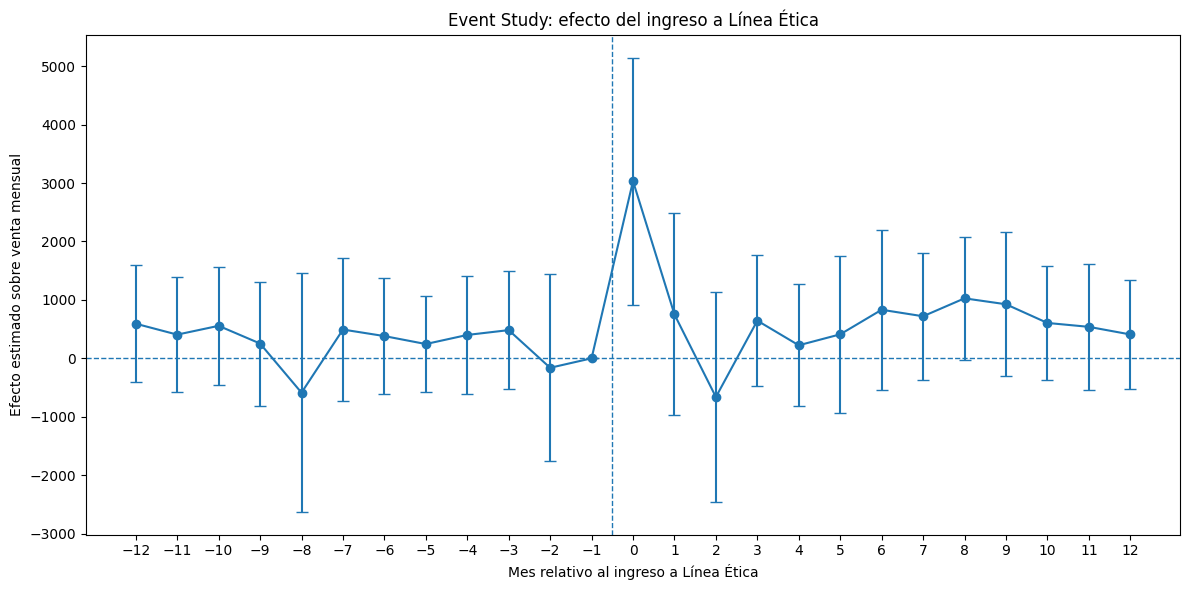

In [87]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

ax.errorbar(
    resultados_evento["mes_relativo"],
    resultados_evento["coeficiente"],
    yerr=1.96 * resultados_evento["error_estandar"],
    fmt="o-",
    capsize=4
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

ax.axvline(
    x=-0.5,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Mes relativo al ingreso a Línea Ética")
ax.set_ylabel("Efecto estimado sobre venta mensual")
ax.set_title(
    "Event Study: efecto del ingreso a Línea Ética"
)

ax.set_xticks(range(-12, 13))

plt.tight_layout()
plt.show()

In [88]:
restricciones_pre = []

for mes in range(-12, -1):

    etiqueta = etiqueta_evento(mes)

    nombre = (
        f'C(evento_cat, Treatment(reference="m1"))'
        f'[T.{etiqueta}]:tratamiento'
    )

    if nombre in modelo_event_study.params:
        restricciones_pre.append(
            f'{nombre} = 0'
        )

prueba_pre = modelo_event_study.f_test(
    ", ".join(restricciones_pre)
)

print(prueba_pre)

<F test: F=0.748954255383082, p=0.6912753837562661, df_denom=539, df_num=11>


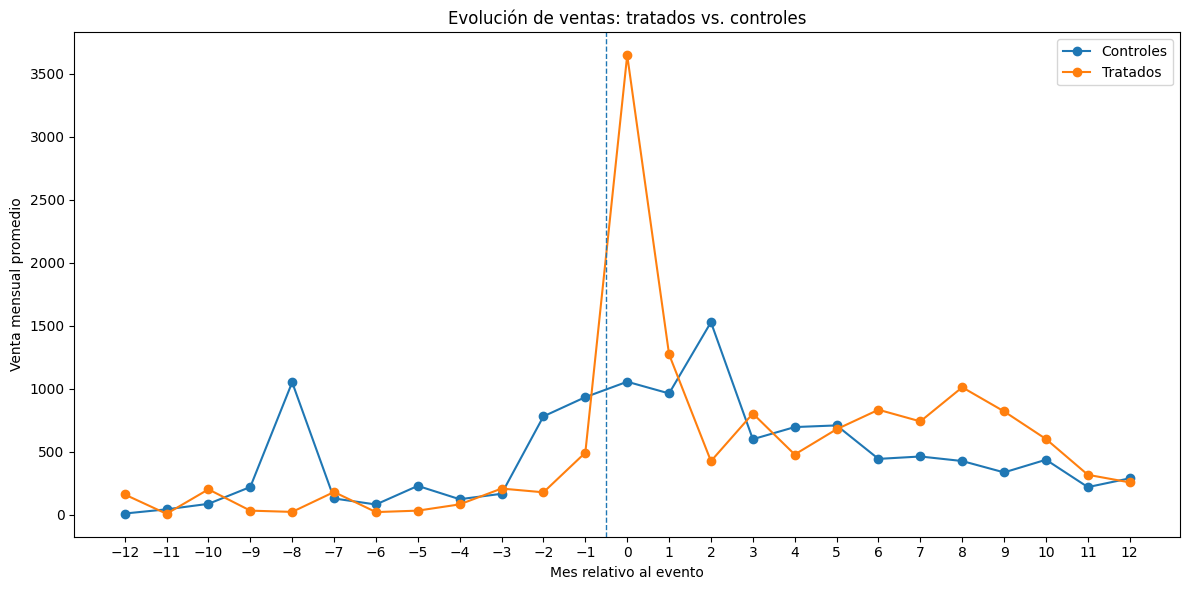

In [89]:
evolucion_promedio = (
    panel_did
    .groupby(
        ["mes_relativo", "tratamiento"]
    )["venta_total"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

for tratamiento, grupo in evolucion_promedio.groupby(
    "tratamiento"
):
    etiqueta = (
        "Tratados"
        if tratamiento == 1
        else "Controles"
    )

    ax.plot(
        grupo["mes_relativo"],
        grupo["venta_total"],
        marker="o",
        label=etiqueta
    )

ax.axvline(
    x=-0.5,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Mes relativo al evento")
ax.set_ylabel("Venta mensual promedio")
ax.set_title(
    "Evolución de ventas: tratados vs. controles"
)

ax.set_xticks(range(-12, 13))
ax.legend()

plt.tight_layout()
plt.show()

In [91]:
print(prueba_pre)

<F test: F=0.748954255383082, p=0.6912753837562661, df_denom=539, df_num=11>


In [92]:
print(
    resultados_evento[
        [
            "mes_relativo",
            "coeficiente",
            "p_value"
        ]
    ].round(3)
)

    mes_relativo  coeficiente  p_value
0            -12      592.400    0.248
1            -11      405.487    0.422
2            -10      556.159    0.282
3             -9      253.250    0.640
4             -8     -588.078    0.572
5             -7      492.379    0.428
6             -6      380.640    0.451
7             -5      244.416    0.559
8             -4      400.051    0.438
9             -3      482.584    0.350
10            -2     -162.064    0.843
11            -1        0.000      NaN
12             0     3033.196    0.005
13             1      750.922    0.394
14             2     -662.215    0.472
15             3      644.615    0.262
16             4      223.128    0.676
17             5      410.469    0.548
18             6      831.155    0.235
19             7      719.651    0.193
20             8     1026.530    0.055
21             9      925.247    0.141
22            10      605.293    0.222
23            11      538.694    0.328
24            12      408

Otra prueba

In [93]:
print("Ventas totales negativas:", (panel_did["venta_total"] < 0).sum())
print("Ventas éticas negativas:", (panel_did["venta_etico"] < 0).sum())
print("Ventas no éticas negativas:", (panel_did["venta_no_etico"] < 0).sum())

Ventas totales negativas: 0
Ventas éticas negativas: 0
Ventas no éticas negativas: 0


In [94]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

panel_did["asinh_venta_total"] = np.arcsinh(
    panel_did["venta_total"]
)

panel_did["asinh_venta_etico"] = np.arcsinh(
    panel_did["venta_etico"]
)

panel_did["asinh_venta_no_etico"] = np.arcsinh(
    panel_did["venta_no_etico"]
)

panel_did["compro"] = (
    panel_did["venta_total"] > 0
).astype(int)

panel_did["post"] = (
    panel_did["mes_relativo"] >= 0
).astype(int)

panel_did["did"] = (
    panel_did["tratamiento"]
    * panel_did["post"]
)

panel_did["mes_calendario"] = (
    pd.to_datetime(panel_did["mes"])
    .dt.to_period("M")
    .astype(str)
)

In [95]:
def estimar_did(variable_dependiente, nombre_resultado):
    
    formula = f"""
        {variable_dependiente}
        ~ did
        + C(codigo_cliente)
        + C(mes_calendario)
    """
    
    modelo = smf.ols(
        formula=formula,
        data=panel_did
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": panel_did["id_pareja"]
        }
    )
    
    coef = modelo.params["did"]
    error = modelo.bse["did"]
    p_value = modelo.pvalues["did"]
    intervalo = modelo.conf_int().loc["did"]
    
    return {
        "resultado": nombre_resultado,
        "coeficiente": coef,
        "error_estandar": error,
        "p_value": p_value,
        "ic_95_inferior": intervalo.iloc[0],
        "ic_95_superior": intervalo.iloc[1],
        "modelo": modelo
    }

In [96]:
resultados_modelos = [
    estimar_did(
        "venta_total",
        "Venta total"
    ),
    
    estimar_did(
        "asinh_venta_total",
        "Venta total transformada"
    ),
    
    estimar_did(
        "venta_etico",
        "Venta ética"
    ),
    
    estimar_did(
        "venta_no_etico",
        "Venta no ética"
    ),
    
    estimar_did(
        "facturas",
        "Cantidad de facturas"
    ),
    
    estimar_did(
        "productos_distintos",
        "Productos distintos"
    ),
    
    estimar_did(
        "compro",
        "Probabilidad mensual de compra"
    )
]

In [97]:
tabla_final = pd.DataFrame([
    {
        "resultado": r["resultado"],
        "coeficiente": r["coeficiente"],
        "error_estandar": r["error_estandar"],
        "p_value": r["p_value"],
        "ic_95_inferior": r["ic_95_inferior"],
        "ic_95_superior": r["ic_95_superior"]
    }
    for r in resultados_modelos
])

tabla_final["significativo_5"] = np.where(
    tabla_final["p_value"] < 0.05,
    "Sí",
    "No"
)

print(
    tabla_final.round(4).to_string(index=False)
)

                     resultado  coeficiente  error_estandar  p_value  ic_95_inferior  ic_95_superior significativo_5
                   Venta total     744.9742        223.3845   0.0009        307.1486       1182.7998              Sí
      Venta total transformada       1.3356          0.0626   0.0000          1.2129          1.4582              Sí
                   Venta ética     296.0873         66.6042   0.0000        165.5454        426.6292              Sí
                Venta no ética     448.8869        169.1611   0.0080        117.3372        780.4366              Sí
          Cantidad de facturas       0.2761          0.0334   0.0000          0.2107          0.3415              Sí
           Productos distintos       1.1264          0.1077   0.0000          0.9154          1.3375              Sí
Probabilidad mensual de compra       0.1803          0.0083   0.0000          0.1639          0.1966              Sí


In [98]:
resultado_transformado = tabla_final.loc[
    tabla_final["resultado"] == "Venta total transformada"
].iloc[0]

beta_transformado = resultado_transformado["coeficiente"]

porcentaje_aproximado = 100 * beta_transformado

porcentaje_exponencial = 100 * (
    np.exp(beta_transformado) - 1
)

print(
    "Coeficiente transformado:",
    round(beta_transformado, 4)
)

print(
    "Aproximación porcentual:",
    round(porcentaje_aproximado, 2),
    "%"
)

print(
    "Transformación exponencial:",
    round(porcentaje_exponencial, 2),
    "%"
)

Coeficiente transformado: 1.3356
Aproximación porcentual: 133.56 %
Transformación exponencial: 280.21 %


In [99]:
panel_did["ticket_promedio"] = np.where(
    panel_did["facturas"] > 0,
    panel_did["venta_total"] / panel_did["facturas"],
    0
)

resultado_ticket = estimar_did(
    "ticket_promedio",
    "Ticket promedio"
)

fila_ticket = pd.DataFrame([{
    "resultado": resultado_ticket["resultado"],
    "coeficiente": resultado_ticket["coeficiente"],
    "error_estandar": resultado_ticket["error_estandar"],
    "p_value": resultado_ticket["p_value"],
    "ic_95_inferior": resultado_ticket["ic_95_inferior"],
    "ic_95_superior": resultado_ticket["ic_95_superior"],
    "significativo_5": (
        "Sí"
        if resultado_ticket["p_value"] < 0.05
        else "No"
    )
}])

tabla_final = pd.concat(
    [tabla_final, fila_ticket],
    ignore_index=True
)

print(
    tabla_final.round(4).to_string(index=False)
)

                     resultado  coeficiente  error_estandar  p_value  ic_95_inferior  ic_95_superior significativo_5
                   Venta total     744.9742        223.3845   0.0009        307.1486       1182.7998              Sí
      Venta total transformada       1.3356          0.0626   0.0000          1.2129          1.4582              Sí
                   Venta ética     296.0873         66.6042   0.0000        165.5454        426.6292              Sí
                Venta no ética     448.8869        169.1611   0.0080        117.3372        780.4366              Sí
          Cantidad de facturas       0.2761          0.0334   0.0000          0.2107          0.3415              Sí
           Productos distintos       1.1264          0.1077   0.0000          0.9154          1.3375              Sí
Probabilidad mensual de compra       0.1803          0.0083   0.0000          0.1639          0.1966              Sí
               Ticket promedio     319.9458         69.5588   0.

In [100]:
tabla_final.to_csv(
    "resultados_finales_did.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Resultados guardados en resultados_finales_did.csv")

Resultados guardados en resultados_finales_did.csv


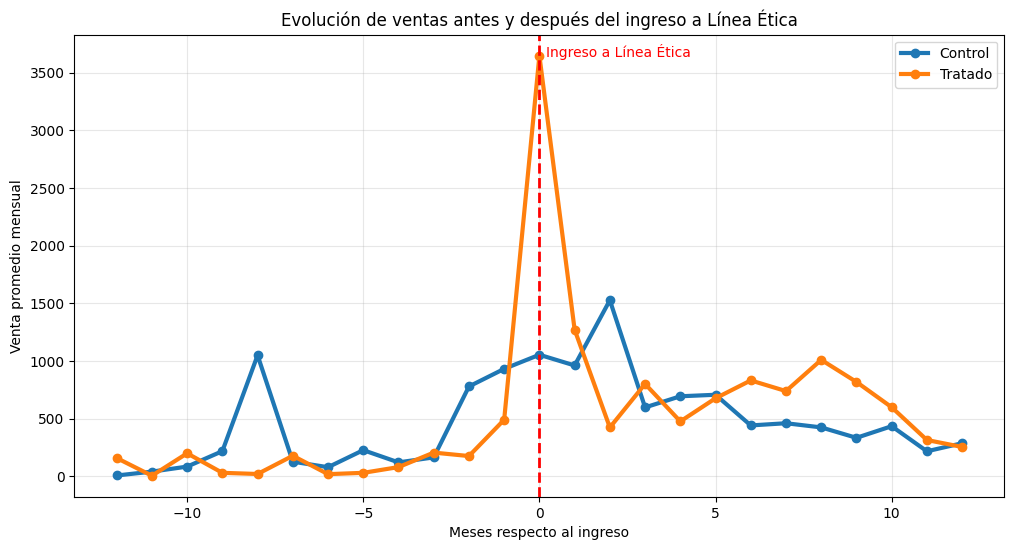

In [101]:
import matplotlib.pyplot as plt

grafico = (
    panel_did
    .groupby(["mes_relativo", "tratamiento"])
    ["venta_total"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12,6))

for t, nombre in [(0,"Control"), (1,"Tratado")]:

    aux = grafico[grafico.tratamiento==t]

    plt.plot(
        aux["mes_relativo"],
        aux["venta_total"],
        marker="o",
        linewidth=3,
        label=nombre
    )

plt.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.text(
    0.2,
    plt.ylim()[1]*0.95,
    "Ingreso a Línea Ética",
    color="red"
)

plt.xlabel("Meses respecto al ingreso")
plt.ylabel("Venta promedio mensual")
plt.title("Evolución de ventas antes y después del ingreso a Línea Ética")

plt.legend()

plt.grid(alpha=.3)

plt.show()

,mes_relativo,venta_promedio,cantidad_clientes
0,-12,159.626185,540
1,-11,6.165185,540
2,-10,200.348185,540
3,-9,31.264148,540
4,-8,21.217333,540


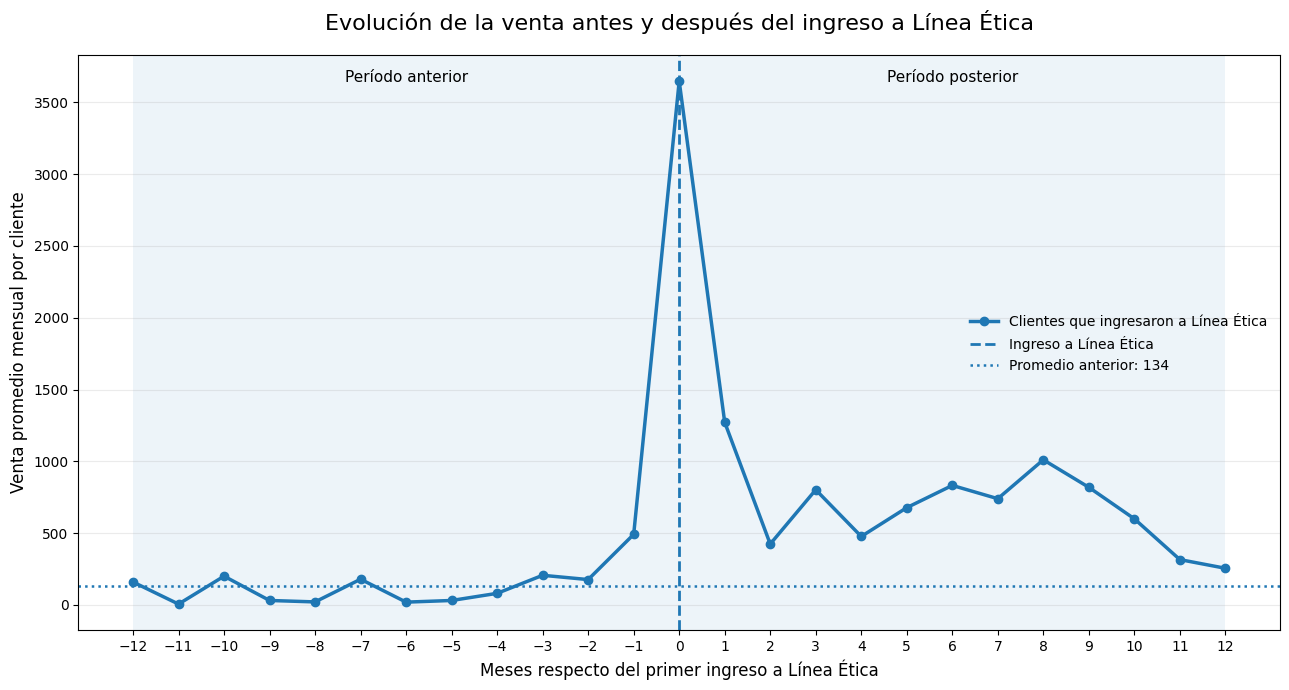

In [103]:
import matplotlib.pyplot as plt
import pandas as pd

# =====================================================
# 1. Venta promedio mensual de los clientes tratados
# =====================================================

tratados = (
    panel_did.loc[
        panel_did["tratamiento"] == 1
    ]
    .groupby("mes_relativo", as_index=False)
    .agg(
        venta_promedio=("venta_total", "mean"),
        cantidad_clientes=("codigo_cliente", "nunique")
    )
    .sort_values("mes_relativo")
)

display(tratados.head())

# =====================================================
# 2. Crear el gráfico
# =====================================================

fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    tratados["mes_relativo"],
    tratados["venta_promedio"],
    marker="o",
    linewidth=2.5,
    label="Clientes que ingresaron a Línea Ética"
)

# Línea vertical: momento de ingreso
ax.axvline(
    x=0,
    linestyle="--",
    linewidth=2,
    label="Ingreso a Línea Ética"
)

# Sombreado antes y después
ax.axvspan(
    tratados["mes_relativo"].min(),
    0,
    alpha=0.08
)

ax.axvspan(
    0,
    tratados["mes_relativo"].max(),
    alpha=0.08
)

# Línea del promedio previo al ingreso
promedio_previo = tratados.loc[
    tratados["mes_relativo"] < 0,
    "venta_promedio"
].mean()

ax.axhline(
    y=promedio_previo,
    linestyle=":",
    linewidth=1.8,
    label=f"Promedio anterior: {promedio_previo:,.0f}"
)

# =====================================================
# 3. Etiquetas y formato
# =====================================================

ax.set_title(
    "Evolución de la venta antes y después del ingreso a Línea Ética",
    fontsize=16,
    pad=18
)

ax.set_xlabel(
    "Meses respecto del primer ingreso a Línea Ética",
    fontsize=12
)

ax.set_ylabel(
    "Venta promedio mensual por cliente",
    fontsize=12
)

ax.set_xticks(
    range(
        int(tratados["mes_relativo"].min()),
        int(tratados["mes_relativo"].max()) + 1
    )
)

ax.text(
    -6,
    ax.get_ylim()[1] * 0.95,
    "Período anterior",
    ha="center",
    fontsize=11
)

ax.text(
    6,
    ax.get_ylim()[1] * 0.95,
    "Período posterior",
    ha="center",
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend(
    frameon=False,
    loc="best"
)

plt.tight_layout()
plt.show()

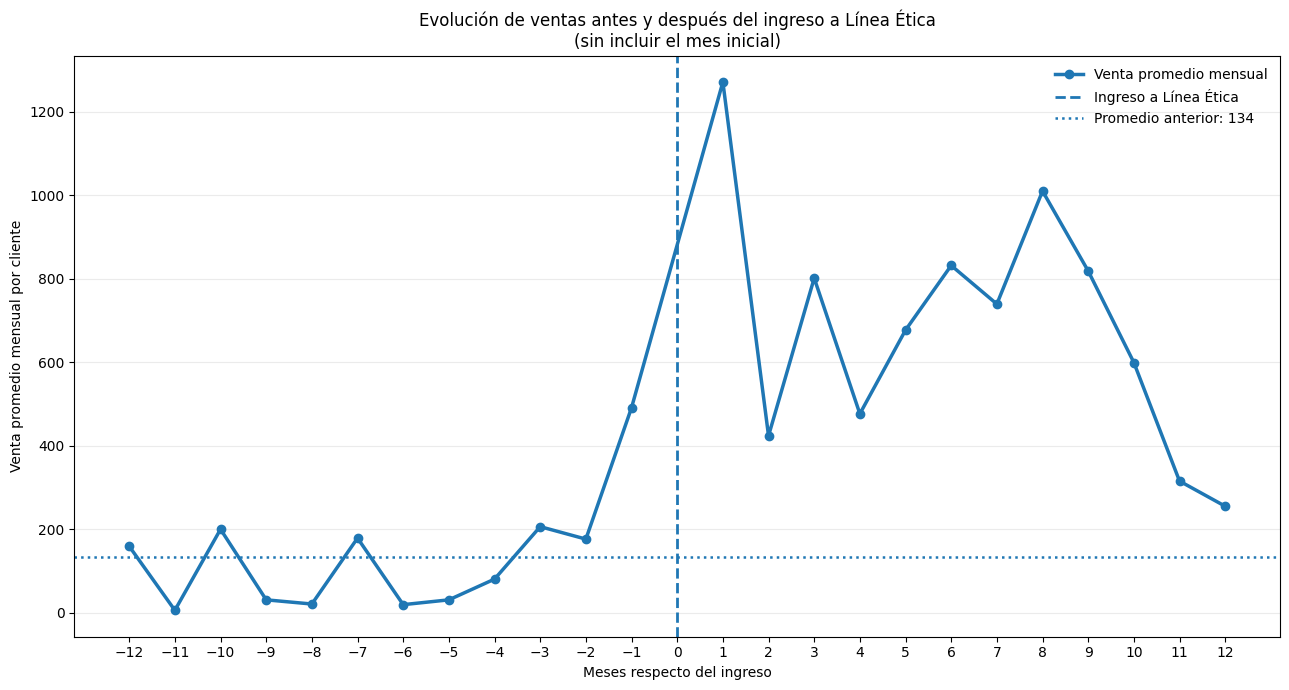

In [104]:
tratados_sin_mes_0 = tratados[
    tratados["mes_relativo"] != 0
]

fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    tratados_sin_mes_0["mes_relativo"],
    tratados_sin_mes_0["venta_promedio"],
    marker="o",
    linewidth=2.5,
    label="Venta promedio mensual"
)

ax.axvline(
    x=0,
    linestyle="--",
    linewidth=2,
    label="Ingreso a Línea Ética"
)

ax.axhline(
    y=promedio_previo,
    linestyle=":",
    linewidth=1.8,
    label=f"Promedio anterior: {promedio_previo:,.0f}"
)

ax.set_title(
    "Evolución de ventas antes y después del ingreso a Línea Ética\n"
    "(sin incluir el mes inicial)"
)

ax.set_xlabel("Meses respecto del ingreso")
ax.set_ylabel("Venta promedio mensual por cliente")

ax.set_xticks(range(-12, 13))
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()